<a href="https://colab.research.google.com/github/PedroHON410/An-lise-explorat-ria-de-vinhos/blob/main/An%C3%A1lise_explorat%C3%B3ria_de_Vinhos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Etapas
- Entendimento de negócio
- Compreensão dos dados
- Análise (extrair informações relevantes para conseguir responder perguntas)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

In [ ]:
df = pd.read_csv("winemag-data-130k-v2.csv")
df.head()

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


## Sumário
* **Unnamed** - Coluna de indice ( pode ser removido ).

* **country** - País onde o vinho foi feito.

* **description** - Descrição do vinho.

* **designation** - Vinhedo dentro da adega de onde as uvas que fizeram o vinho foram coletadas.

* **points** - Numero de pontos que o vinho obteve em sua avaliação (precisamos entender a escala de pontos).

* **price** - Preço da garrafa de vinho.

* **province** - Provincia (estado) onde o vinho foi feito.

* **region_1** - Região onde o vinho foi feito.

* **region_2** - Região específica de uma vinícula.

* **taster_name** - Nome do revisor.

* **taster_twitter_handle** - Perfil do Twitter do avaliador.

* **title** - Nome do vinho analisado (o ano de fabricação está no título).

* **variety** - Tipo de uvas utilizadas na fabricação do vinho.

* **winery** - Adega onde o vinho foi feito.

## Perguntas
1. **De qual país vem o melhor vinho ?**

2. **Existe relação do preço do vinho com a qualidade ?**

3. **Existem tipos de uvas com melhor qualidade ?**

4. **Qual o melhor vinho em cada faixa de preço ?**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43904 entries, 0 to 43903
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             43904 non-null  int64  
 1   country                43886 non-null  object 
 2   description            43904 non-null  object 
 3   designation            31330 non-null  object 
 4   points                 43904 non-null  int64  
 5   price                  40778 non-null  float64
 6   province               43885 non-null  object 
 7   region_1               36681 non-null  object 
 8   region_2               16864 non-null  object 
 9   taster_name            34901 non-null  object 
 10  taster_twitter_handle  33242 non-null  object 
 11  title                  43903 non-null  object 
 12  variety                43903 non-null  object 
 13  winery                 43903 non-null  object 
dtypes: float64(1), int64(2), object(11)
memory usage: 4.7+

In [6]:
df.describe()

,Unnamed: 0,points,price
count,43904.000000,43904.000000,40778.000000
mean,21951.500000,88.404678,35.107999
std,12674.137446,3.014981,39.980654
min,0.000000,80.000000,3.000000
25%,10975.750000,86.000000,17.000000
50%,21951.500000,88.000000,25.000000
75%,32927.250000,91.000000,42.000000
max,43903.000000,100.000000,2500.000000


## Tabela de classificação por pontos

* **98-100** - Clássico
* **94-97** - Soberbo
* **90-93** - Excelente
* **87-89** - Muito bom
* **83-86** - Bom
* **80-82** - Aceitável

In [7]:
df["country"].value_counts()

,count
country,
US,18191
France,7432
Italy,6787
Spain,2238
Portugal,1974
Chile,1499
Argentina,1319
Austria,1126
Australia,774


In [8]:
df["variety"].value_counts()

,count
variety,
Pinot Noir,4450
Chardonnay,3853
Cabernet Sauvignon,3174
Red Blend,3075
Bordeaux-style Red Blend,2345
...,...
Thrapsathiri,1
Fer Servadou,1
Paralleda,1


## Limpeza dos dados

In [18]:
df1 = df.copy()

In [19]:
df1 = df1.drop(["Unnamed: 0", "region_1", "region_2", "taster_name", "taster_twitter_handle"], axis=1)
df1.head()

,country,description,designation,points,price,province,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [20]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43904 entries, 0 to 43903
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      43886 non-null  object 
 1   description  43904 non-null  object 
 2   designation  31330 non-null  object 
 3   points       43904 non-null  int64  
 4   price        40778 non-null  float64
 5   province     43885 non-null  object 
 6   title        43903 non-null  object 
 7   variety      43903 non-null  object 
 8   winery       43903 non-null  object 
dtypes: float64(1), int64(1), object(7)
memory usage: 3.0+ MB


In [27]:
print("{:.0%}".format(df1["price"].count()/df1.shape[0]))

93%


In [77]:
df1 = df1.dropna()
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29108 entries, 1 to 43902
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   country      29108 non-null  object 
 1   description  29108 non-null  object 
 2   designation  29108 non-null  object 
 3   points       29108 non-null  int64  
 4   price        29108 non-null  float64
 5   province     29108 non-null  object 
 6   title        29108 non-null  object 
 7   variety      29108 non-null  object 
 8   winery       29108 non-null  object 
dtypes: float64(1), int64(1), object(7)
memory usage: 2.2+ MB


## Análise exploratória

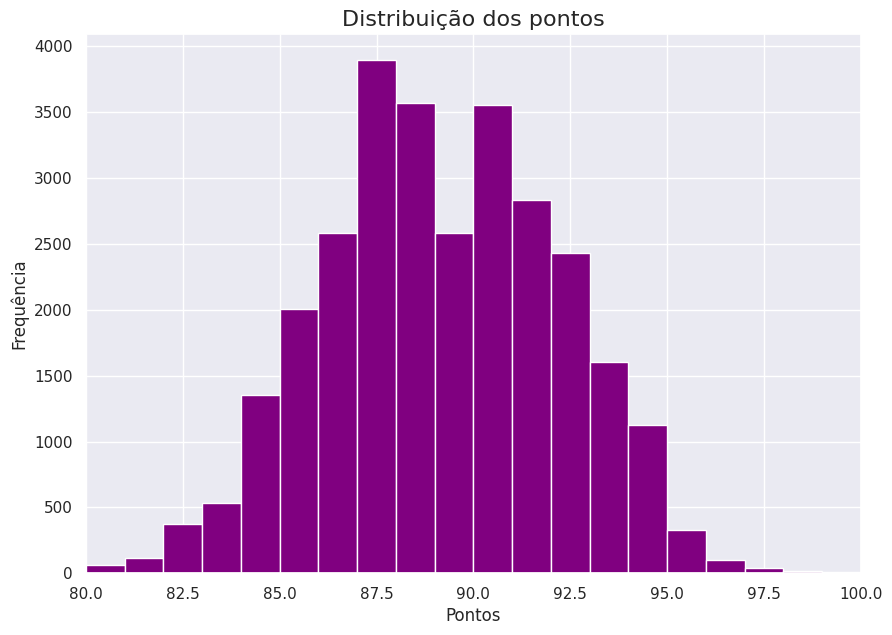

In [78]:
plt.figure(figsize=(10, 7))
plt.hist(data=df1, x="points",
          bins=20,
         color="purple")
plt.xlim(80,100)
plt.title("Distribuição dos pontos", fontsize=16)
plt.xlabel("Pontos")
plt.ylabel("Frequência");

In [79]:
vinhos_top_10 = df1['country'].value_counts()[:10]
vinhos_top_10

,count
country,
US,12285
Italy,4180
France,3936
Spain,1788
Portugal,1515
Chile,1292
Argentina,1003
Austria,815
Germany,647


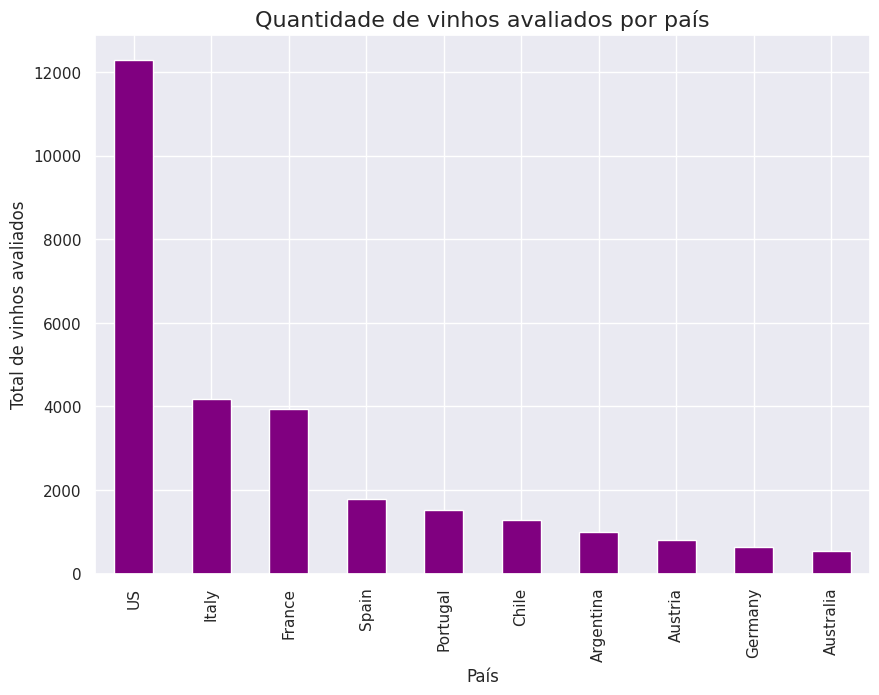

In [80]:
plt.figure(figsize=(10, 7))
vinhos_top_10.plot(kind="bar", color="purple")
plt.title("Quantidade de vinhos avaliados por país", fontsize=16)
plt.xlabel("País")
plt.ylabel("Total de vinhos avaliados");

In [81]:
melhor_qualidade = df1.groupby("country")[["points", "price"]].mean()
melhor_qualidade_top10 = melhor_qualidade.sort_values(by="points", ascending=False)[:10]
melhor_qualidade_top10.style.background_gradient(cmap="Purples", high=0.5, subset=["points"])

,points,price
country,,
India,93.000000,20.000000
England,91.500000,56.750000
Austria,90.390184,32.588957
Switzerland,90.000000,30.000000
Germany,89.941267,43.775889
Hungary,89.566667,47.766667
Canada,89.419355,39.870968
France,89.070122,41.083841
Macedonia,89.000000,20.000000


/tmp/ipykernel_1234/3654199503.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=x, y=y, palette="Purples_r")


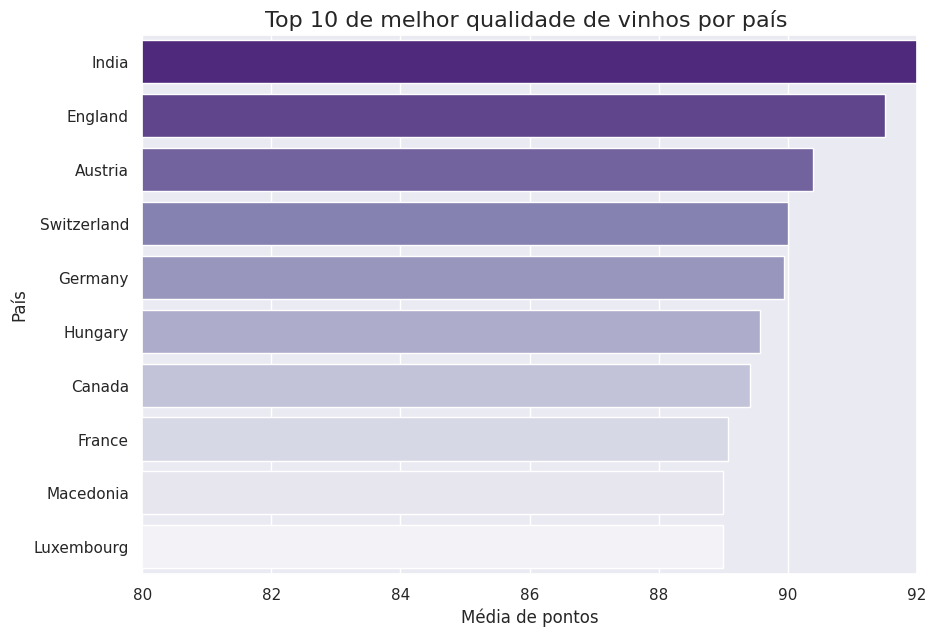

In [82]:
x = melhor_qualidade_top10["points"]
y = melhor_qualidade_top10.index

plt.figure(figsize=(10,7))
plt.xlim(80,92)
sns.barplot(x=x, y=y, palette="Purples_r")
plt.title("Top 10 de melhor qualidade de vinhos por país ", fontsize=16)
plt.xlabel("Média de pontos")
plt.ylabel("País");

In [83]:
acima_95_pontos = df1[df1["points"] >= 95]
acima_95_pontos['country'].value_counts()

,count
country,
US,244
France,88
Italy,78
Germany,22
Portugal,16
Australia,16
Austria,14
Spain,12
Argentina,2


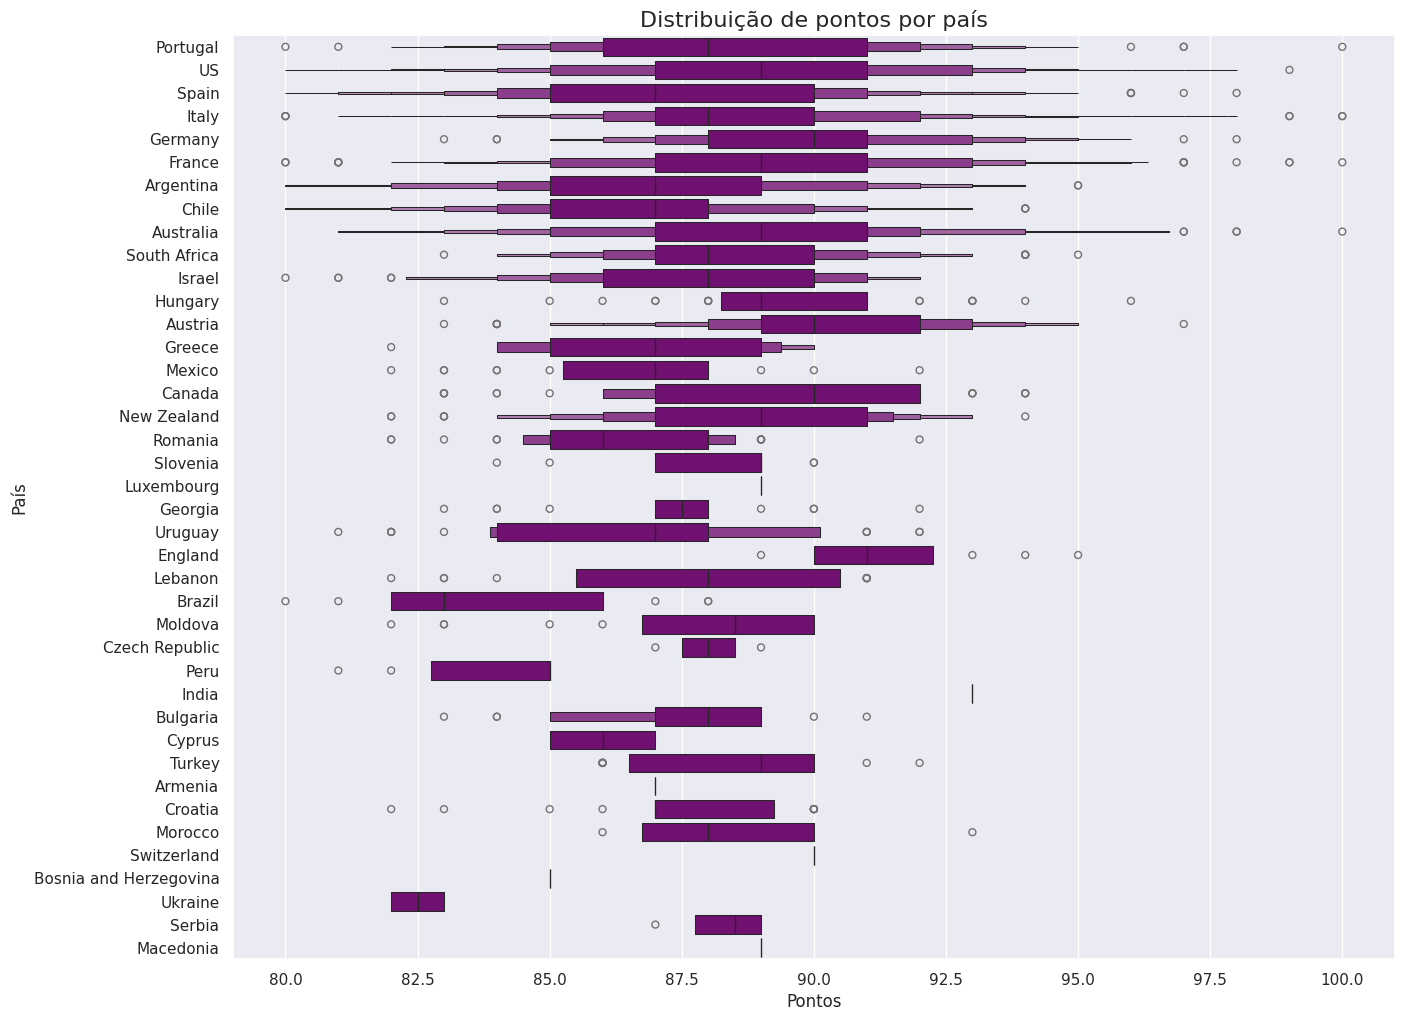

In [84]:
plt.figure(figsize=(15, 12))
sns.boxenplot(data=df1, x='points', y='country', color="purple")
plt.title("Distribuição de pontos por país", fontsize=16)
plt.xlabel("Pontos")
plt.ylabel("País");

/tmp/ipykernel_1234/2731762139.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=x, y=y, palette="Purples_r")


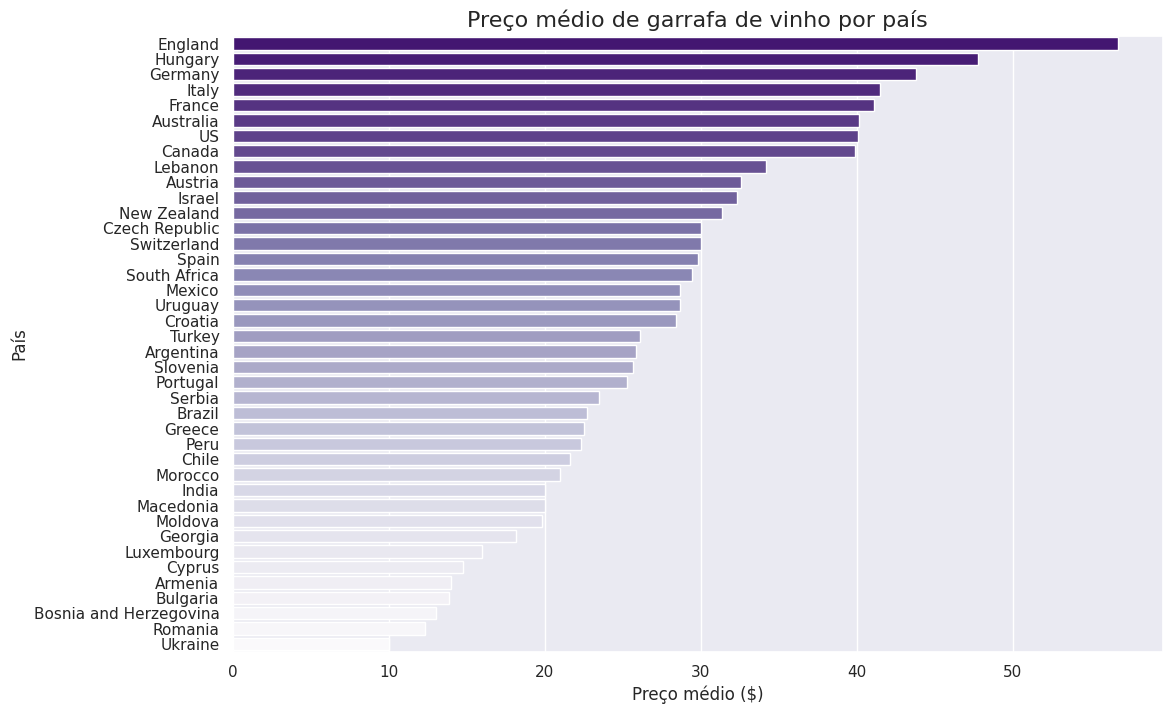

In [85]:
preco_medio = df1.groupby("country")[["price"]].mean()
preco_medio = preco_medio.sort_values(by="price", ascending=False)
y = preco_medio.index.to_series()
x = preco_medio["price"]

plt.figure(figsize=(12,8))
sns.barplot(x=x, y=y, palette="Purples_r")
plt.title("Preço médio de garrafa de vinho por país", fontsize=16)
plt.xlabel("Preço médio ($)")
plt.ylabel("País");

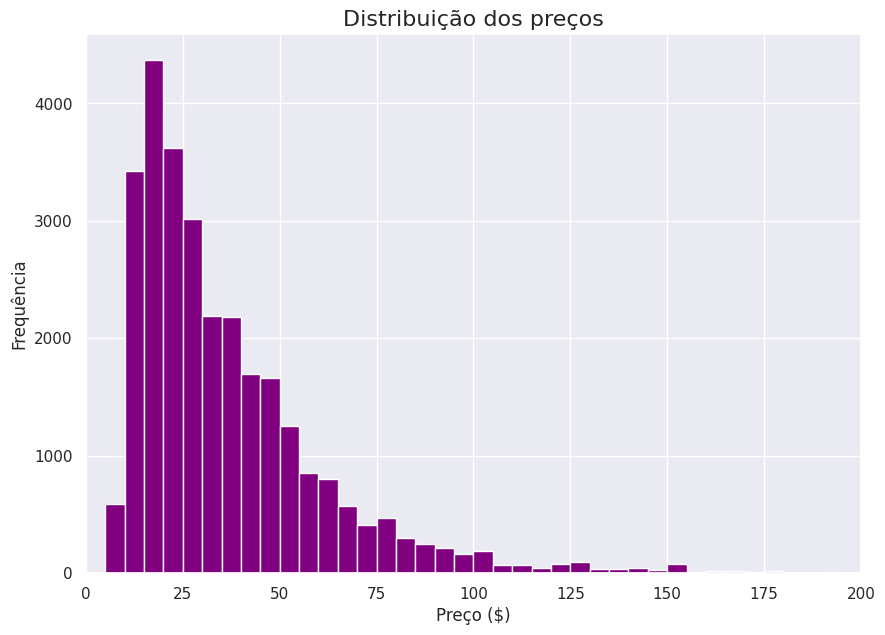

In [86]:
plt.figure(figsize=(10, 7))
bins = np.arange(0, df1['price'].max()+5, 5)
plt.hist(data=df1, x="price",
          bins=bins,
         color="purple")
plt.xlim(0, 200)
plt.title("Distribuição dos preços", fontsize=16)
plt.xlabel("Preço ($)")
plt.ylabel("Frequência");

In [87]:
df1['price'].describe()

,price
count,29108.000000
mean,37.167102
std,35.566922
min,4.000000
25%,18.000000
50%,28.000000
75%,45.000000
max,1000.000000


In [88]:
np.log10(df1['price'].describe())

,price
count,4.464012
mean,1.570159
std,1.551046
min,0.602060
25%,1.255273
50%,1.447158
75%,1.653213
max,3.000000


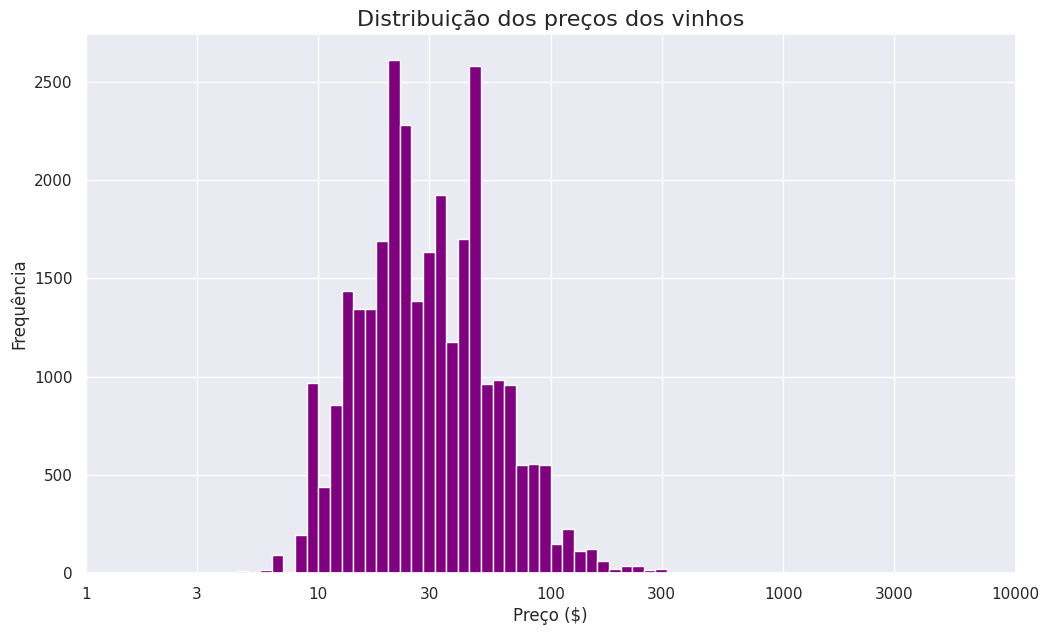

In [89]:
plt.figure(figsize=(12, 7))
bins = 10 ** np.arange(0.5, 2.5+0.05, 0.05)
valores = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000]
plt.hist(data=df1, x="price",
          bins=bins,
         color="purple")
plt.title('Distribuição dos preços dos vinhos', fontsize=16)
plt.xscale('log')
plt.xticks(valores, valores)
plt.xlabel("Preço ($)")
plt.ylabel("Frequência");

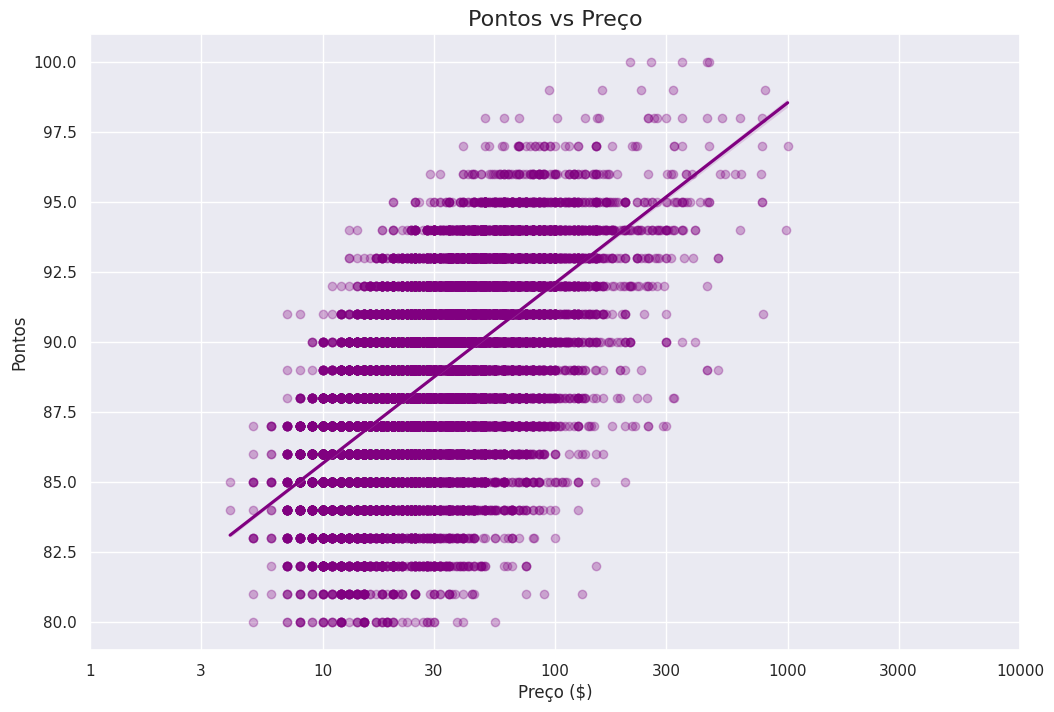

In [90]:
x = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000]

plt.figure(figsize=(12, 8))
sns.regplot(x='price', y='points', data=df1, color="purple", logx=True, scatter_kws={'alpha':0.3})
plt.title("Pontos vs Preço", fontsize=16)
plt.xscale('log')
plt.xticks(x, x)
plt.xlabel("Preço ($)")
plt.ylabel("Pontos");

In [91]:
df1[df1['price'] == df1['price'].min()][:1]

,country,description,designation,points,price,province,title,variety,winery
1987,Spain,Berry and cherry aromas are surprisingly sturd...,Flirty Bird,85,4.0,Central Spain,Felix Solis 2013 Flirty Bird Syrah (Vino de la...,Syrah,Felix Solis


In [92]:
df1[df1['price'] == df1['price'].max()][:1]

,country,description,designation,points,price,province,title,variety,winery
36531,Portugal,This Port was “rescued” from the darkest reces...,90-year Old Tawny,97,1000.0,Port,W. & J. Graham's NV 90-year Old Tawny (Port),Port,W. & J. Graham's


In [93]:
df1['variety'].value_counts()[:20]

,count
variety,
Pinot Noir,3161
Chardonnay,2435
Red Blend,2401
Cabernet Sauvignon,1923
Riesling,1456
Syrah,1015
Bordeaux-style Red Blend,973
Sauvignon Blanc,936
Rosé,749


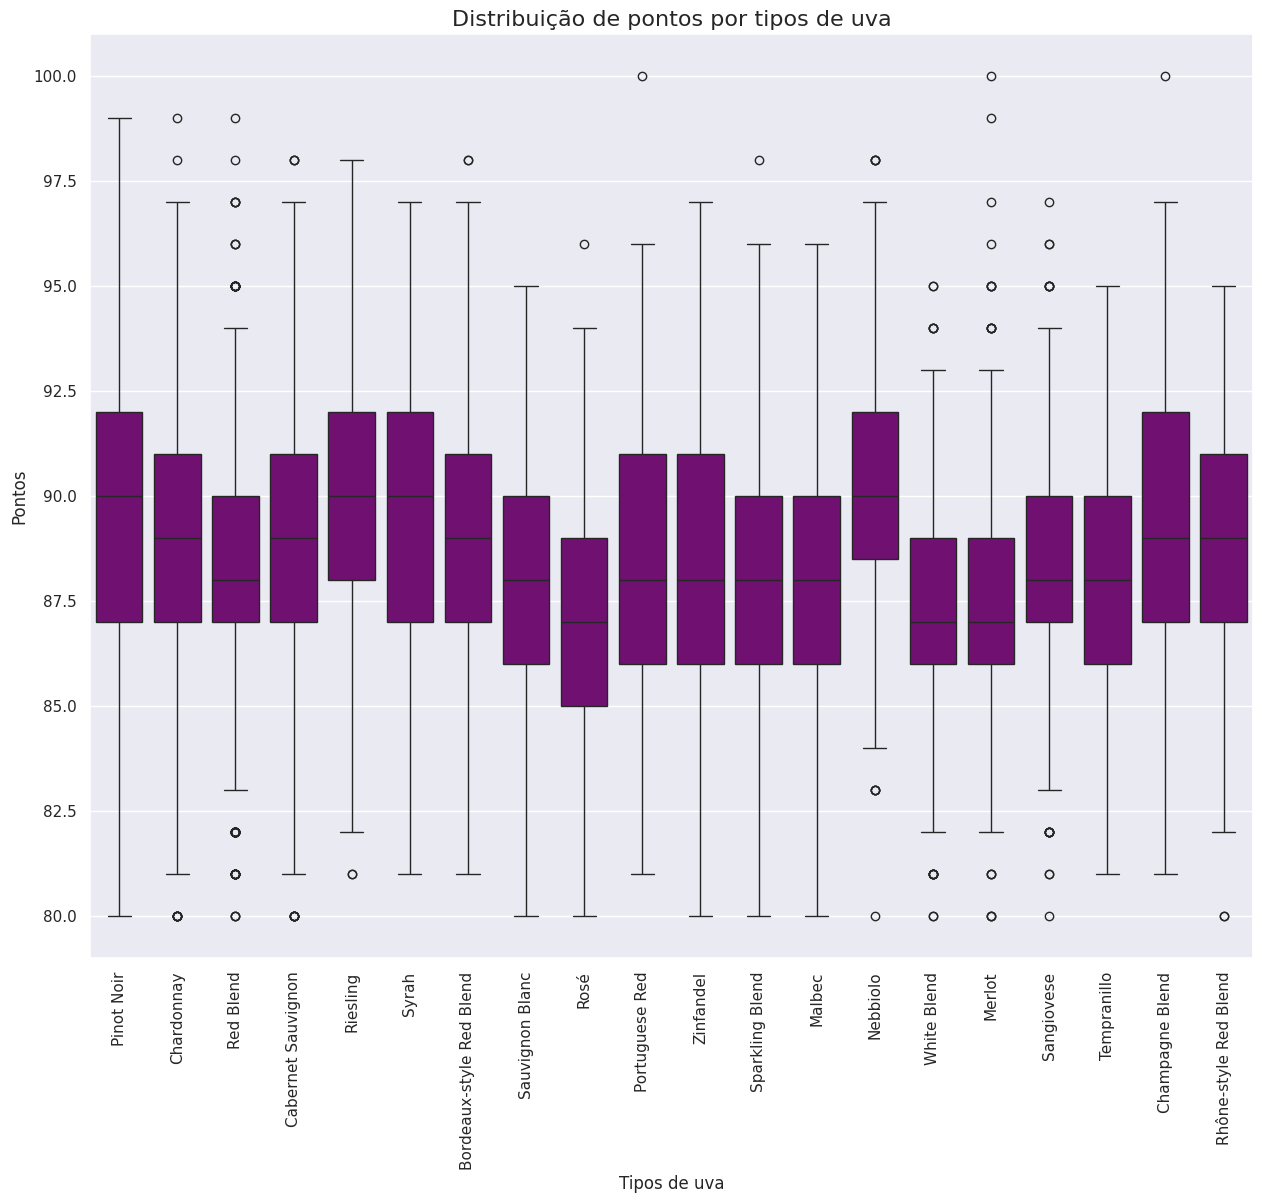

In [94]:
plt.figure(figsize=(15, 12))
sns.boxplot(data=df1,
            y='points',
            x='variety',
            color="purple",
            order=df1['variety'].value_counts()[:20].index)
plt.title("Distribuição de pontos por tipos de uva", fontsize=16)
plt.xlabel("Tipos de uva")
plt.ylabel("Pontos")
plt.xticks(rotation=90);

## Qual o melhor vinho em cada faixa de preço ?

* Até $15

* Entre $15 e 30

* Entre $30 e 50

* Acima de $50

## Top 10 vinhos até $15

In [95]:
df2 = df1.drop(['description', 'province', 'winery'], axis=1)
ate_15 = df2[df2['price'] <= 15]
ate_15 = ate_15.sort_values(by="points", ascending=False)[:10]
ate_15.style.background_gradient(cmap="YlOrRd", high=0.5, subset=["price"])

,country,designation,points,price,title,variety
19136,Spain,Pedro Ximenez 1827 Sweet Sherry,94,14.000000,Osborne NV Pedro Ximenez 1827 Sweet Sherry Sherry (Jerez),Sherry
23974,Portugal,Assobio,94,13.000000,Quinta dos Murças 2011 Assobio Red (Douro),Portuguese Red
9609,France,Prestige,93,13.000000,Château Vincens 2011 Prestige Malbec-Merlot (Cahors),Malbec-Merlot
22871,Portugal,Follies Casa da Agueira,93,13.000000,Aveleda 2012 Follies Casa da Agueira Touriga Nacional (Bairrada),Touriga Nacional
43193,US,Oley Dessert Wine,93,14.000000,Novy 2006 Oley Dessert Wine Viognier (Russian River Valley),Viognier
37882,Australia,Sarah's Blend,93,15.000000,Marquis Philips 2000 Sarah's Blend Red (South Eastern Australia),Red Blend
9458,Austria,Kremser Weinberge,92,14.000000,Türk 2015 Kremser Weinberge Grüner Veltliner (Kremstal),Grüner Veltliner
9446,Austria,Gebling,92,15.000000,Buchegger 2015 Gebling Grüner Veltliner (Kremstal),Grüner Veltliner
7381,US,Glacier Estate Vineyard,92,14.000000,AntoLin Cellars 2010 Glacier Estate Vineyard Riesling (Yakima Valley),Riesling
3017,Austria,Andau,92,13.000000,Scheiblhofer 2010 Andau Zweigelt (Burgenland),Zweigelt


## Top 10 vinhos entre $15 e 30

In [97]:
entre_15_30 = df2.query("15 <= price <= 30")
entre_15_30 = entre_15_30.sort_values(by="points", ascending=False)[:10]
entre_15_30.style.background_gradient(cmap="YlOrRd", high=0.5, subset=["price"])

,country,designation,points,price,title,variety
9901,France,Saering Grand Cru,96,29.000000,Domaines Schlumberger 2014 Saering Grand Cru Riesling (Alsace),Riesling
5011,US,Lewis Estate Vineyard,95,20.000000,Dunham 2010 Lewis Estate Vineyard Riesling (Columbia Valley (WA)),Riesling
4523,Italy,Contrada Monte San Nicolò,95,30.000000,Biondi 2014 Contrada Monte San Nicolò (Etna),Red Blend
9907,France,Kastelberg Grand Cru Schiste,95,25.000000,Julien Schaal 2016 Kastelberg Grand Cru Schiste Riesling (Alsace),Riesling
9915,France,Goldert Grand Cru,95,26.000000,Domaine Zind-Humbrecht 2015 Goldert Grand Cru Muscat (Alsace),Muscat
26894,Austria,Gaisberg Reserve,95,29.000000,Eichinger 2015 Gaisberg Reserve Riesling (Kamptal),Riesling
27608,Italy,Praepositus,95,25.000000,Abbazia di Novacella 2015 Praepositus Kerner (Alto Adige),Kerner
4527,Italy,Pithos Rosso,95,30.000000,COS 2014 Pithos Rosso Red (Vittoria),Red Blend
15196,France,Château Bouscassé,95,20.000000,Alain Brumont 2010 Château Bouscassé Red (Madiran),Red Blend
43644,France,Symphonie de Novembre,95,25.000000,Domaine Cauhapé 2012 Symphonie de Novembre (Jurançon),Petit Manseng


##Top 10 entre $30 e 50

In [98]:
entre_30_50 = df2.query("30 <= price <= 50")
entre_30_50 = entre_30_50.sort_values(by="points", ascending=False)[:10]
entre_30_50.style.background_gradient(cmap="YlOrRd", high=0.5, subset=["price"])

,country,designation,points,price,title,variety
1560,US,Red Wine,98,50.000000,Pirouette 2008 Red Wine Red (Columbia Valley (WA)),Bordeaux-style Red Blend
16524,Portugal,325 Anniversary,97,40.000000,Taylor Fladgate NV 325 Anniversary (Port),Port
4504,US,Rocky Knoll,97,50.000000,Limerick Lane 2013 Rocky Knoll Zinfandel (Russian River Valley),Zinfandel
26892,US,Wedding Cuvée Estate Bottled,96,44.000000,Iron Horse 2012 Wedding Cuvée Estate Bottled Sparkling (Green Valley),Sparkling Blend
16528,US,Ribbon Ridge Estate Dry,96,32.000000,Trisaetum 2016 Ribbon Ridge Estate Dry Riesling (Ribbon Ridge),Riesling
15851,US,Estate,96,40.000000,Stolo 2014 Estate Syrah (San Luis Obispo County),Syrah
33845,US,Las Hermanas Vineyard,96,44.000000,Samsara 2008 Las Hermanas Vineyard Pinot Noir (Sta. Rita Hills),Pinot Noir
9903,France,Rangen de Thann Grand Cru,96,45.000000,Julien Schaal 2016 Rangen de Thann Grand Cru Riesling (Alsace),Riesling
9904,France,Geisberg Grand Cru,96,42.000000,Kuentz-Bas 2015 Geisberg Grand Cru Riesling (Alsace),Riesling
41841,US,Special Selected Late Harvest Botrytis,96,45.000000,Macauley 2007 Special Selected Late Harvest Botrytis Sémillon (Alexander Valley),Sémillon


## Top 10 acima de $50

In [99]:
acima_50 = df2.query("price >= 50")
acima_50 = acima_50.sort_values(by="points", ascending=False)[:10]
acima_50.style.background_gradient(cmap="YlOrRd", high=0.5, subset=["price"])

,country,designation,points,price,title,variety
7335,Italy,Occhio di Pernice,100,210.000000,Avignonesi 1995 Occhio di Pernice (Vin Santo di Montepulciano),Prugnolo Gentile
42197,Portugal,Barca-Velha,100,450.000000,Casa Ferreirinha 2008 Barca-Velha Red (Douro),Portuguese Red
345,Australia,Rare,100,350.000000,Chambers Rosewood Vineyards NV Rare Muscat (Rutherglen),Muscat
39286,Italy,Masseto,100,460.000000,Tenuta dell'Ornellaia 2007 Masseto Merlot (Toscana),Merlot
36528,France,Brut,100,259.000000,Krug 2002 Brut (Champagne),Champagne Blend
39287,Italy,Messorio,99,320.000000,Le Macchiole 2007 Messorio Merlot (Toscana),Merlot
35517,Italy,Sassicaia,99,235.000000,Tenuta San Guido 2012 Sassicaia (Bolgheri Sassicaia),Red Blend
41835,France,Cuvée Constance 500ml,99,159.000000,Domaine Huët 2009 Cuvée Constance 500ml (Vouvray),Chenin Blanc
36529,France,Clos du Mesnil Brut Blanc de Blancs,99,800.000000,Krug 2002 Clos du Mesnil Brut Blanc de Blancs Chardonnay (Champagne),Chardonnay
1557,US,Precious Mountain Vineyard,99,94.000000,Williams Selyem 2009 Precious Mountain Vineyard Pinot Noir (Sonoma Coast),Pinot Noir


# Conclusão

- **De qual país vem o melhor vinho?**

  R: A Inglaterra é quem produz em média produz mais vínhos soberbos (Já que índia tem poucas avaliações).

- **Preço e qualidade estão relacionados?**

  R: Sim, a qualidade é sempre maior quando o preço também é maior. (Mas existem algumas exceções)


- **Existem tipos de uva com melhor qualidade?**

  R: Pinot Noir, Chardonnay e Red Blend são as três variedades com melhores avaliações.




- **Qual o melhor vinho em cada faixa de preço?**

**(Baseado no melhor custo benefício feito pelos dados.)**

    Até $15:
     
    Portugal	| Assobio |	Pontos: 94 |	$13

    Entre $15 e 30:
    
    US | Lewis Estate Vineyard | Pontos: 95 |	$20

    Entre $30 e 50:
    
    US |	Red Wine	| Pontos: 98	| $50

    Acima de $50:
    
    France |	Brut	| Pontos: 100	| $259


